# KNN Fruit Classification
**Dataset:** apple, banana, mango, orange, tomato

**Pipeline:**
* hog_hsv:(HOG + HSV Histogram) → StandardScaler → PCA → KNN
* full:(HOG + HSV Histogram + LBP) → StandardScaler → PCA → KNN
* full_v2: (HOG + Color Histogram + LBP + Color Moments + Hu Moments) → StandardScaler → PCA → KNN


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Import thư viện

In [ ]:
import os
import json
import numpy as np
import cv2
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog, local_binary_pattern
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)


## 2. Config

In [ ]:
DATASET_DIR = '/content/drive/MyDrive/CS231.Q21/dataset/fruit'
MODEL_DIR   = '/content/drive/MyDrive/CS231.Q21/models'
IMG_SIZE    = (224, 224)
LABEL_MAP   = {'apple': 0, 'banana': 1, 'mango': 2, 'orange': 3, 'tomato': 4}

# HOG params — (8,8)
HOG_ORIENTATIONS    = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)

# LBP params
LBP_RADIUS   = 3
LBP_N_POINTS = 8 * LBP_RADIUS

# Color Histogram params (HSV)
HSV_BINS = [16, 8, 4]

# PCA
PCA_VARIANCE = 0.98

# KNN
K_VALUES = [3, 5, 7, 9, 11]

os.makedirs(MODEL_DIR, exist_ok=True)
print(f'Model sẽ lưu tại: {MODEL_DIR}')

Model sẽ lưu tại: /content/drive/MyDrive/CS231.Q21/models


## 3. Tiền xử lý dữ liệu



### 3.1 Resize & Normalize pixel
> - **Resize** về 224×224 (chuẩn ImageNet, thống nhất với CNN/ResNet).
> - **Normalize** pixel `[0–255] → [0, 1]` trước khi trích đặc trưng.

In [ ]:
def preprocess_image(img_bgr, img_size=IMG_SIZE):
    img_resized   = cv2.resize(img_bgr, img_size)
    img_normalized = img_resized.astype(np.float32) / 255.0
    return img_normalized

sample_dir  = os.path.join(DATASET_DIR, 'train', list(LABEL_MAP.keys())[0])
sample_file = os.listdir(sample_dir)[0]
sample_img  = cv2.imread(os.path.join(sample_dir, sample_file))

processed = preprocess_image(sample_img)


3.2 Label Encoding

In [ ]:
IDX_TO_LABEL = {v: k for k, v in LABEL_MAP.items()}

print('Label Encoding:')
for name, idx in LABEL_MAP.items():
    print(f'  {name:<10} → {idx}')

Label Encoding:
  apple      → 0
  banana     → 1
  mango      → 2
  orange     → 3
  tomato     → 4


3.3 Kiểm tra ảnh trước và sau khi processing


Ảnh gốc   : shape=(168, 299, 3), dtype=uint8, 
            pixel range=[0, 255]
Sau xử lý : shape=(224, 224, 3), dtype=float32, 
            pixel range=[0.00, 1.00]


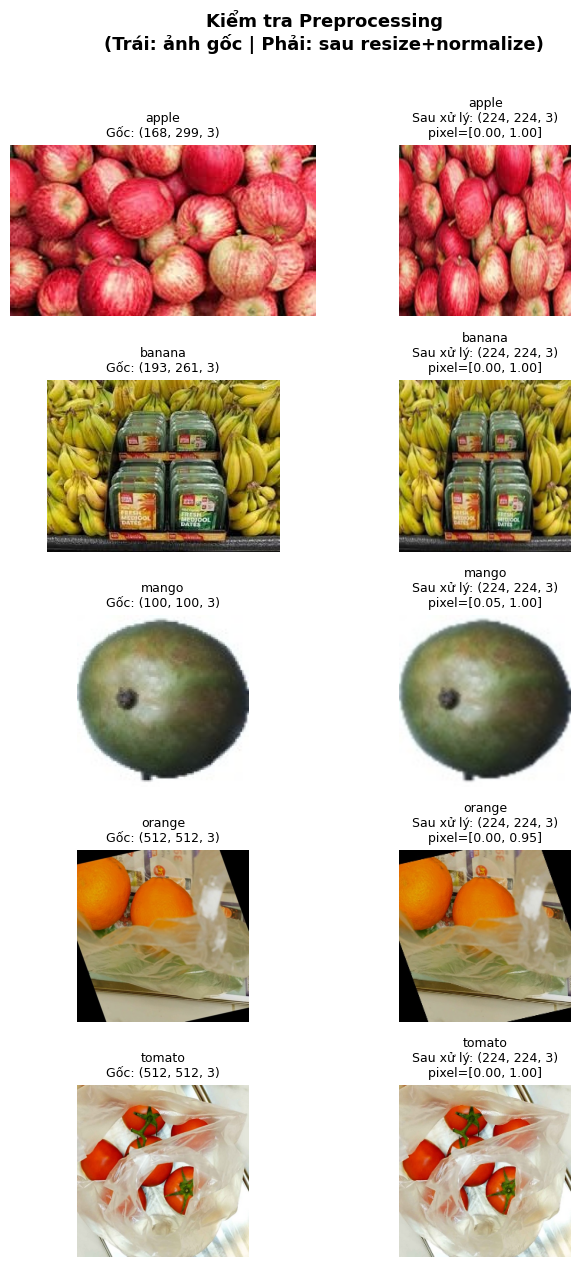

In [ ]:
print(f'Ảnh gốc   : shape={sample_img.shape}, dtype={sample_img.dtype}, ')
print(f'            pixel range=[{sample_img.min()}, {sample_img.max()}]')
print(f'Sau xử lý : shape={processed.shape}, dtype={processed.dtype}, ')
print(f'            pixel range=[{processed.min():.2f}, {processed.max():.2f}]')

def show_preprocessing_check(dataset_dir, label_map, n_per_class=1):
    classes = list(label_map.keys())
    fig, axes = plt.subplots(len(classes), 2, figsize=(7, len(classes) * 2.5))
    fig.suptitle('Kiểm tra Preprocessing\n(Trái: ảnh gốc | Phải: sau resize+normalize)',
                 fontsize=13, fontweight='bold', y=1.01)

    for row, cls in enumerate(classes):
        cls_dir = os.path.join(dataset_dir, 'train', cls)
        fname   = os.listdir(cls_dir)[0]
        fpath   = os.path.join(cls_dir, fname)

        img_orig = cv2.imread(fpath)
        img_proc = preprocess_image(img_orig)  # resize + normalize

        # OpenCV đọc BGR -> chuyển RGB để matplotlib hiển thị đúng màu
        orig_rgb = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
        proc_rgb = cv2.cvtColor((img_proc * 255).astype('uint8'), cv2.COLOR_BGR2RGB)

        # Ảnh gốc
        axes[row, 0].imshow(orig_rgb)
        axes[row, 0].set_title(f'{cls}\nGốc: {img_orig.shape}', fontsize=9)
        axes[row, 0].axis('off')

        # Ảnh sau preprocessing
        axes[row, 1].imshow(proc_rgb)
        axes[row, 1].set_title(
            f'{cls}\nSau xử lý: {img_proc.shape}\n'
            f'pixel=[{img_proc.min():.2f}, {img_proc.max():.2f}]',
            fontsize=9
        )
        axes[row, 1].axis('off')

    plt.tight_layout()
    plt.show()

show_preprocessing_check(DATASET_DIR, LABEL_MAP)

4. Load ảnh (after processing)

In [ ]:
def load_images_from_split(split: str):
    split_dir = os.path.join(DATASET_DIR, split)
    images, labels = [], []

    for class_name, class_idx in LABEL_MAP.items():
        class_dir = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_dir):
            print(f'[WARN] Không tìm thấy thư mục: {class_dir}')
            continue
        for fname in os.listdir(class_dir):
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            img = cv2.imread(os.path.join(class_dir, fname))
            if img is None:
                continue
            img = preprocess_image(img)
            images.append(img)
            labels.append(class_idx)

    print(f'[{split}] Đọc được {len(images)} ảnh (shape={images[0].shape})')
    return images, labels

train_imgs, train_labels = load_images_from_split('train')
val_imgs,   val_labels   = load_images_from_split('val')
test_imgs,  test_labels  = load_images_from_split('test')

y_train = np.array(train_labels)
y_val   = np.array(val_labels)
y_test  = np.array(test_labels)

[train] Đọc được 4200 ảnh (shape=(224, 224, 3))
[val] Đọc được 900 ảnh (shape=(224, 224, 3))
[test] Đọc được 900 ảnh (shape=(224, 224, 3))


5. Trích đặc trưng (HOG + HSV + LBP)

In [ ]:
def extract_hog(img_gray):
    return hog(
        img_gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        channel_axis=None
    )

def extract_color_histogram(img_bgr):
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([img_hsv], [0, 1, 2], None, HSV_BINS,
                        [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

def extract_color_moments(img_bgr):
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    moments = []
    for ch in range(3):  # H, S, V
        channel = img_hsv[:, :, ch]
        mean  = np.mean(channel)
        std   = np.std(channel)
        skew  = np.mean(((channel - mean) / (std + 1e-6)) ** 3)
        moments.extend([mean, std, skew])
    return np.array(moments, dtype=np.float32)

def extract_hu_moments(img_gray):
    moments = cv2.moments(img_gray)
    hu = cv2.HuMoments(moments).flatten()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-10)
    return hu.astype(np.float32)

def extract_lbp(img_gray):
    lbp = local_binary_pattern(img_gray, LBP_N_POINTS, LBP_RADIUS, method='uniform')
    n_bins = LBP_N_POINTS + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist.astype(np.float32)


def extract_features(images, config='full'):
    """
    Configs:
    'hog_hsv'  — HOG + Color Histogram
    'full'     — HOG + Color Histogram + LBP
    'full_v2'  — HOG + Color Histogram + LBP + Color Moments + Hu Moments
    """
    vecs = []
    for img_bgr in images:
        img_u8   = (img_bgr * 255).astype(np.uint8) if img_bgr.dtype != np.uint8 else img_bgr
        gray     = cv2.cvtColor(img_u8, cv2.COLOR_BGR2GRAY)

        hog_f    = extract_hog(gray)
        color_f  = extract_color_histogram(img_u8)

        if config == 'full_v2':
            lbp_f    = extract_lbp(gray)
            moment_f = extract_color_moments(img_u8)
            hu_f     = extract_hu_moments(gray)
            vec = np.concatenate([hog_f, color_f, lbp_f, moment_f, hu_f])
        elif config == 'full':
            lbp_f = extract_lbp(gray)
            vec = np.concatenate([hog_f, color_f, lbp_f])
        else:  # hog_hsv
            vec = np.concatenate([hog_f, color_f])

        vecs.append(vec)
    print(f'  → Vector shape: {vecs[0].shape[0]} chiều (config={config})')
    return np.array(vecs)

6. So sánh 3 cấu hình đặc trưng và chọn K tốt nhất

In [ ]:
results_summary = {}

for config in ['hog_hsv', 'full', 'full_v2']:
    print(f'\n--- Config: {config} ---')
    print('Trích đặc trưng train...')
    X_train_raw = extract_features(train_imgs, config)
    print('Trích đặc trưng val...')
    X_val_raw   = extract_features(val_imgs, config)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw)
    X_val_scaled   = scaler.transform(X_val_raw)

    pca = PCA(n_components=PCA_VARIANCE, random_state=42)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_val_pca   = pca.transform(X_val_scaled)
    print(f'  → Sau PCA: {X_train_pca.shape[1]} chiều')

    #GridSearchCV để tìm tham số tối ưu
    from sklearn.model_selection import GridSearchCV
    from sklearn.neighbors import KNeighborsClassifier

    print("Đang tìm kiếm bộ tham số tối ưu nhất cho KNN (Grid Search)...")

    # 1. Khởi tạo mô hình KNN gốc
    knn_base = KNeighborsClassifier()

    # 2. Định nghĩa không gian tham số cần thử nghiệm
    param_grid = {
        'n_neighbors': [3, 5, 7, 9, 11, 13, 15],       # Thử nhiều giá trị K hơn
        'weights': ['uniform', 'distance'],            # uniform: trọng số đều, distance: gần thì ảnh hưởng cao hơn
        'metric': ['euclidean', 'manhattan', 'cosine'] # Các công thức đo khoảng cách khác nhau
    }

    # 3. Sử dụng GridSearchCV với Cross-Validation (cv=5)
    grid_search = GridSearchCV(
        estimator=knn_base,
        param_grid=param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1,     # Sử dụng tất cả nhân CPU để chạy nhanh hơn
        verbose=2
    )

    # 4. Huấn luyện để tìm ra tham số tốt nhất
    grid_search.fit(X_train_pca, y_train)

    # 5. Lấy ra mô hình tốt nhất
    best_model = grid_search.best_estimator_

    print("-" * 50)
    print(f"Tham số tốt nhất tìm được: {grid_search.best_params_}")
    print(f"Độ chính xác (Accuracy) tốt nhất trên tập train (CV): {grid_search.best_score_:.4f}")

    # Đánh giá trên tập validation
    val_acc = accuracy_score(y_val, best_model.predict(X_val_pca))
    print(f"Độ chính xác trên tập Validation: {val_acc:.4f}")
    print("-" * 50)

    results_summary[config] = {
        'best_params': grid_search.best_params_,
        'cv_acc': grid_search.best_score_,
        'val_acc': val_acc,
        'model': best_model,
        'scaler': scaler,
        'pca': pca
    }

print('\n Bảng so sánh các cấu hình:')
print(f"  {'Config':<12} {'Best Params':<40} {'CV Acc':<10} {'Val Acc'}")
print(f"  {'-'*75}")
for cfg, res in results_summary.items():
    params_str = str(res['best_params'])[:35] + '...' if len(str(res['best_params'])) > 35 else str(res['best_params'])
    mark = ' ←' if res['val_acc'] == max(r['val_acc'] for r in results_summary.values()) else ''
    print(f"  {cfg:<12} {params_str:<40} {res['cv_acc']:.4f}     {res['val_acc']:.4f}{mark}")


--- Config: hog_hsv ---
Trích đặc trưng train...
  → Vector shape: 26756 chiều (config=hog_hsv)
Trích đặc trưng val...
  → Vector shape: 26756 chiều (config=hog_hsv)
  → Sau PCA: 3199 chiều
Đang tìm kiếm bộ tham số tối ưu nhất cho KNN (Grid Search)...
Fitting 5 folds for each of 42 candidates, totalling 210 fits
--------------------------------------------------
Tham số tốt nhất tìm được: {'metric': 'cosine', 'n_neighbors': 3, 'weights': 'distance'}
Độ chính xác (Accuracy) tốt nhất trên tập train (CV): 0.6910
Độ chính xác trên tập Validation: 0.5822
--------------------------------------------------

--- Config: full ---
Trích đặc trưng train...
  → Vector shape: 26782 chiều (config=full)
Trích đặc trưng val...
  → Vector shape: 26782 chiều (config=full)
  → Sau PCA: 3199 chiều
Đang tìm kiếm bộ tham số tối ưu nhất cho KNN (Grid Search)...
Fitting 5 folds for each of 42 candidates, totalling 210 fits
--------------------------------------------------
Tham số tốt nhất tìm được: {'metric

7. Evaluate trên Test Set

In [ ]:

best_config = max(results_summary, key=lambda c: results_summary[c]['val_acc'])
print(f"Config tốt nhất: '{best_config}'")

best   = results_summary[best_config]
scaler = best['scaler']
pca    = best['pca']
model  = best['model']

print('Trích đặc trưng test...')
X_test_raw    = extract_features(test_imgs, best_config)
X_test_scaled = scaler.transform(X_test_raw)
X_test_pca    = pca.transform(X_test_scaled)
y_pred        = model.predict(X_test_pca)

class_names = list(LABEL_MAP.keys())
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec  = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1   = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f'\nAccuracy : {acc:.4f}')
print(f'Precision: {prec:.4f}')
print(f'Recall   : {rec:.4f}')
print(f'F1-score : {f1:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=class_names))


Config tốt nhất: 'hog_hsv'
Trích đặc trưng test...
  → Vector shape: 26756 chiều (config=hog_hsv)

Accuracy : 0.5644
Precision: 0.5731
Recall   : 0.5644
F1-score : 0.5646

Classification Report:
              precision    recall  f1-score   support

       apple       0.69      0.52      0.59       180
      banana       0.63      0.66      0.65       180
       mango       0.49      0.59      0.53       180
      orange       0.53      0.47      0.49       180
      tomato       0.53      0.59      0.56       180

    accuracy                           0.56       900
   macro avg       0.57      0.56      0.56       900
weighted avg       0.57      0.56      0.56       900



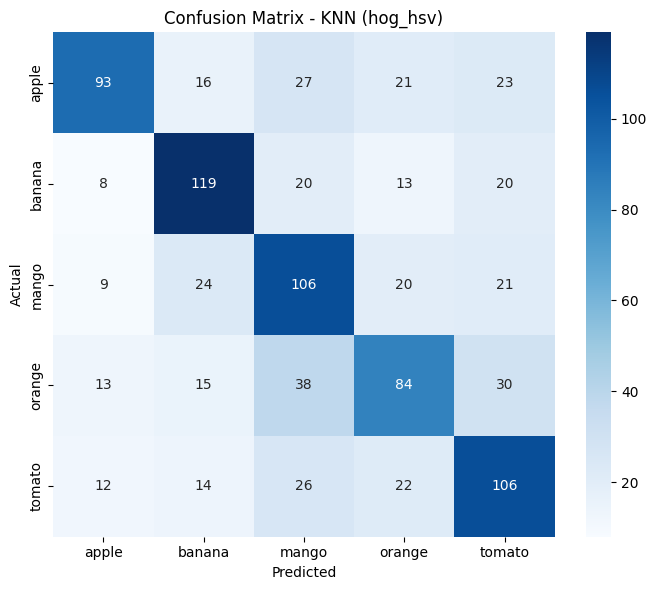

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - KNN ({best_config})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'knn_confusion_matrix.png'), dpi=150)
plt.show()

8. Lưu Model + Metadata


In [ ]:
joblib.dump(model,  os.path.join(MODEL_DIR, 'knn_best.pkl'))
joblib.dump(scaler, os.path.join(MODEL_DIR, 'knn_scaler.pkl'))
joblib.dump(pca,    os.path.join(MODEL_DIR, 'knn_pca.pkl'))

metadata = {
    'best_config': best_config,
    'label_map': LABEL_MAP,
    'img_size': list(IMG_SIZE),
    'pca_variance': PCA_VARIANCE,
    'best_params': results_summary[best_config]['best_params'],
    'metrics_test': {
        'accuracy': float(acc),
        'precision_macro': float(prec),
        'recall_macro': float(rec),
        'f1_macro': float(f1)
    }
}

with open(os.path.join(MODEL_DIR, 'knn_metadata.json'), 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print('Đã lưu model:')
print(f'{MODEL_DIR}/knn_best.pkl')
print(f'{MODEL_DIR}/knn_scaler.pkl')
print(f'{MODEL_DIR}/knn_pca.pkl')
print(f'{MODEL_DIR}/knn_metadata.json')
print(f'{MODEL_DIR}/knn_confusion_matrix.png')

Đã lưu model:
/content/drive/MyDrive/CS231.Q21/models/knn_best.pkl
/content/drive/MyDrive/CS231.Q21/models/knn_scaler.pkl
/content/drive/MyDrive/CS231.Q21/models/knn_pca.pkl
/content/drive/MyDrive/CS231.Q21/models/knn_metadata.json
/content/drive/MyDrive/CS231.Q21/models/knn_confusion_matrix.png
